# $$ NeurIPS \ 2025 - PolyPred| v1.1 $$

# $$ Setup $$

In [1]:
# ==================== CONFIGURATIONS ====================
class CFG:
    
    EXTRA_TRAIN_PATH = ''
    TRAIN_PATH       = '/kaggle/input/neurips-open-polymer-prediction-2025/train.csv'
    TEST_PATH        = '/kaggle/input/neurips-open-polymer-prediction-2025/test.csv'
    TARGETS          = ['Tg', 'Rg', 'FFV', 'Density', 'Tc']

    FOLDS = 5
    SEED  = 42

    LGBM_PARAMS = {
        'objective': 'regression',
        'metric': 'mae',
        'boosting_type': 'gbdt',
        'num_leaves': 150,           
        'learning_rate': 0.08,       
        'feature_fraction': 0.8,     
        'bagging_fraction': 0.8,     
        'lambda_l1': 0.1,            
        'lambda_l2': 0.1,            
        'min_data_in_leaf': 10,      
        'device': 'cpu',
        'verbose': -1,
        'random_state': 42
        }

In [2]:
# ==================== INSTALL & IMPORT LIBRARIES ====================

# !pip install ydata_profiling
# =========================================================================

import pandas as pd
import numpy as np
import random
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================================

# Sets the seed for reproducibility in numpy, random, torch CPU, and CUDA.
np.random.seed(CFG.SEED)
random.seed(CFG.SEED)
torch.manual_seed(CFG.SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(CFG.SEED)
    torch.cuda.manual_seed_all(CFG.SEED) # For multi-GPU setups.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False #May slightly slow down training, but ensures reproducibility

# =========================================================================
# Set plot style
sns.set_style('whitegrid')

# # Silence FutureWarning
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
# ==================== HELPER FUNCTIONS ====================

def iqr_outlier_capping(train, valid=None, test=None, columns=None):
    """
    Applies IQR-based outlier capping to specified columns of one, two, or three DataFrames.

    Parameters:
        train (pd.DataFrame): The training DataFrame used to calculate IQR thresholds.
        valid (pd.DataFrame, optional): The validation DataFrame to cap using train thresholds.
        test (pd.DataFrame, optional): The test DataFrame to cap using train thresholds.
        columns (list, optional): List of column names to apply capping to. If None, applies to all numerical columns.

    Returns:
        tuple: A tuple containing:
            - train_capped (pd.DataFrame): Capped training DataFrame.
            - valid_capped (pd.DataFrame or None): Capped validation DataFrame (if provided).
            - test_capped (pd.DataFrame or None): Capped test DataFrame (if provided).

    Note: Make sure there are no nans
    """
    train_capped = train.copy() # Avoid modifying the original DataFrame
    valid_capped = valid.copy() if valid is not None else None
    test_capped = test.copy() if test is not None else None

    if columns is None:
        columns = train.select_dtypes(include='number').columns.tolist()  # All numerical columns

    # Calculate IQR-based thresholds from the training set
    # w/ .dropna() to handle cols with nans: required by np.percentile
    for col in columns:
        Q1 = np.percentile(train[col].dropna(), 25)
        Q3 = np.percentile(train[col].dropna(), 75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Show Values
        # print(f'Columns {col}: \tLower Bound is: {lower_bound:.2f} \tUpper Bound is: {upper_bound:.2f}')

        # Cap outliers in the training set
        train_capped[col] = np.clip(train_capped[col], lower_bound, upper_bound)

        # If validation set is provided, cap using training set thresholds
        if valid is not None:
            valid_capped[col] = np.clip(valid[col], lower_bound, upper_bound)

        # If test set is provided, cap using training set thresholds
        if test is not None:
            test_capped[col] = np.clip(test[col], lower_bound, upper_bound)

    return train_capped, valid_capped, test_capped
    
    # EXAMPLE USE: TRAIN_capped, _, TEST_capped = iqr_outlier_capping(TRAIN_DF.dropna(), None, TEST_DF, columns=TRAIN_DF.select_dtypes('number').columns.difference([target]))

# ============================================================
def print_with_sep(text,sep="=",n=30):
  print("\n")
  print(sep*n)
  print('\t',text)
  print(sep*n)

# ============================================================
def print_dataset_overview(datasets):

    # Check shapes
    print_with_sep("Shapes")
    for name, df in datasets.items():
      print(f"{name} shape: {df.shape}")
    
    # Check duplicates
    print_with_sep("Duplicates")
    for name, df in datasets.items():
      print(f"{name} duplicates: {df.duplicated().sum()}")
    
    # Check nans
    print_with_sep("NaNs")
    for name, df in datasets.items():
      print(f"{name} NaNs: {df.isnull().sum().sum()}")
    
    # Check col difference
    print_with_sep("Columns not in test")
    print(set(TRAIN_DF.columns).difference(set(TEST_DF.columns)))

    # Check descriptive stats
    print_with_sep("Descriptive Statistics")
    for name, df in datasets.items():
      print(f"{name} Description:")
      percentage_missing = df.isnull().sum()/df.shape[0]; percentage_missing.name = '% Missing'
      data_types = df.dtypes; data_types.name = 'd_type'
    
      display(
          pd.concat([
              df.describe(include='all').T,
              percentage_missing,
              data_types],
                    axis=1).replace(np.nan,'-').style.background_gradient(cmap='Blues'))
      print("\n")

In [4]:
import os

# Load datasets (on Kaggle)
TRAIN_DF = pd.read_csv(CFG.TRAIN_PATH, index_col = 'id')
TEST_DF = pd.read_csv(CFG.TEST_PATH, index_col = 'id')
if CFG.EXTRA_TRAIN_PATH != '':
    TRAIN_EXTRA = pd.read_csv(CFG.EXTRA_TRAIN_PATH)

TRAIN_DF.head()

# # Load datasets (on Colab)
# TRAIN_DF = pd.read_csv(os.path.join(playground_series_s5e8_path, 'train.csv'),index_col = 'id')
# TEST_DF = pd.read_csv(os.path.join(playground_series_s5e8_path, 'test.csv'),index_col = 'id')
# # TRAIN_EXTRA = pd.read_csv(os.path.join(playground_series_s5e8_path_extra, '.csv')) dtype=str

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,SMILES,Tg,FFV,Tc,Density,Rg
id,,,,,,
87817,*CC(*)c1ccccc1C(=O)OCCCCCC,NaN,0.374645,0.205667,NaN,NaN
106919,*Nc1ccc([C@H](CCC)c2ccc(C3(c4ccc([C@@H](CCC)c5...,NaN,0.370410,NaN,NaN,NaN
388772,*Oc1ccc(S(=O)(=O)c2ccc(Oc3ccc(C4(c5ccc(Oc6ccc(...,NaN,0.378860,NaN,NaN,NaN
519416,*Nc1ccc(-c2c(-c3ccc(C)cc3)c(-c3ccc(C)cc3)c(N*)...,NaN,0.387324,NaN,NaN,NaN
539187,*Oc1ccc(OC(=O)c2cc(OCCCCCCCCCOCC3CCCN3c3ccc([N...,NaN,0.355470,NaN,NaN,NaN


In [5]:
TEST_DF.dtypes

SMILES    object
dtype: object

In [6]:
# Store data in datasets
datasets = {
    'TRAIN_DF': TRAIN_DF,
    'TEST_DF': TEST_DF,
    }

# Datasets' overview
print_dataset_overview(datasets)



	 Shapes
TRAIN_DF shape: (7973, 6)
TEST_DF shape: (3, 1)


	 Duplicates
TRAIN_DF duplicates: 0
TEST_DF duplicates: 0


	 NaNs
TRAIN_DF NaNs: 30360
TEST_DF NaNs: 0


	 Columns not in test
{'FFV', 'Tc', 'Density', 'Tg', 'Rg'}


	 Descriptive Statistics
TRAIN_DF Description:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max,% Missing,d_type
SMILES,7973.000000,7973,*CC(*)c1ccccc1C(=O)OCCCCCC,1,-,-,-,-,-,-,-,0.000000,object
Tg,511.000000,-,-,-,96.452314,111.228279,-148.029738,13.674509,74.040183,161.147595,472.250000,0.935909,float64
FFV,7030.000000,-,-,-,0.367212,0.029609,0.226992,0.349549,0.364264,0.380790,0.777097,0.118274,float64
Tc,737.000000,-,-,-,0.256334,0.089538,0.046500,0.186000,0.236000,0.330500,0.524000,0.907563,float64
Density,613.000000,-,-,-,0.985484,0.146189,0.748691,0.890243,0.948193,1.062096,1.840999,0.923116,float64
Rg,614.000000,-,-,-,16.419787,4.608640,9.728355,12.540328,15.052194,20.411067,34.672906,0.922990,float64




TEST_DF Description:


,count,unique,top,freq,% Missing,d_type
SMILES,3,3,*Oc1ccc(C=NN=Cc2ccc(Oc3ccc(C(c4ccc(*)cc4)(C(F)(F)F)C(F)(F)F)cc3)cc2)cc1,1,0.000000,object


# $$ Target Analysis$$

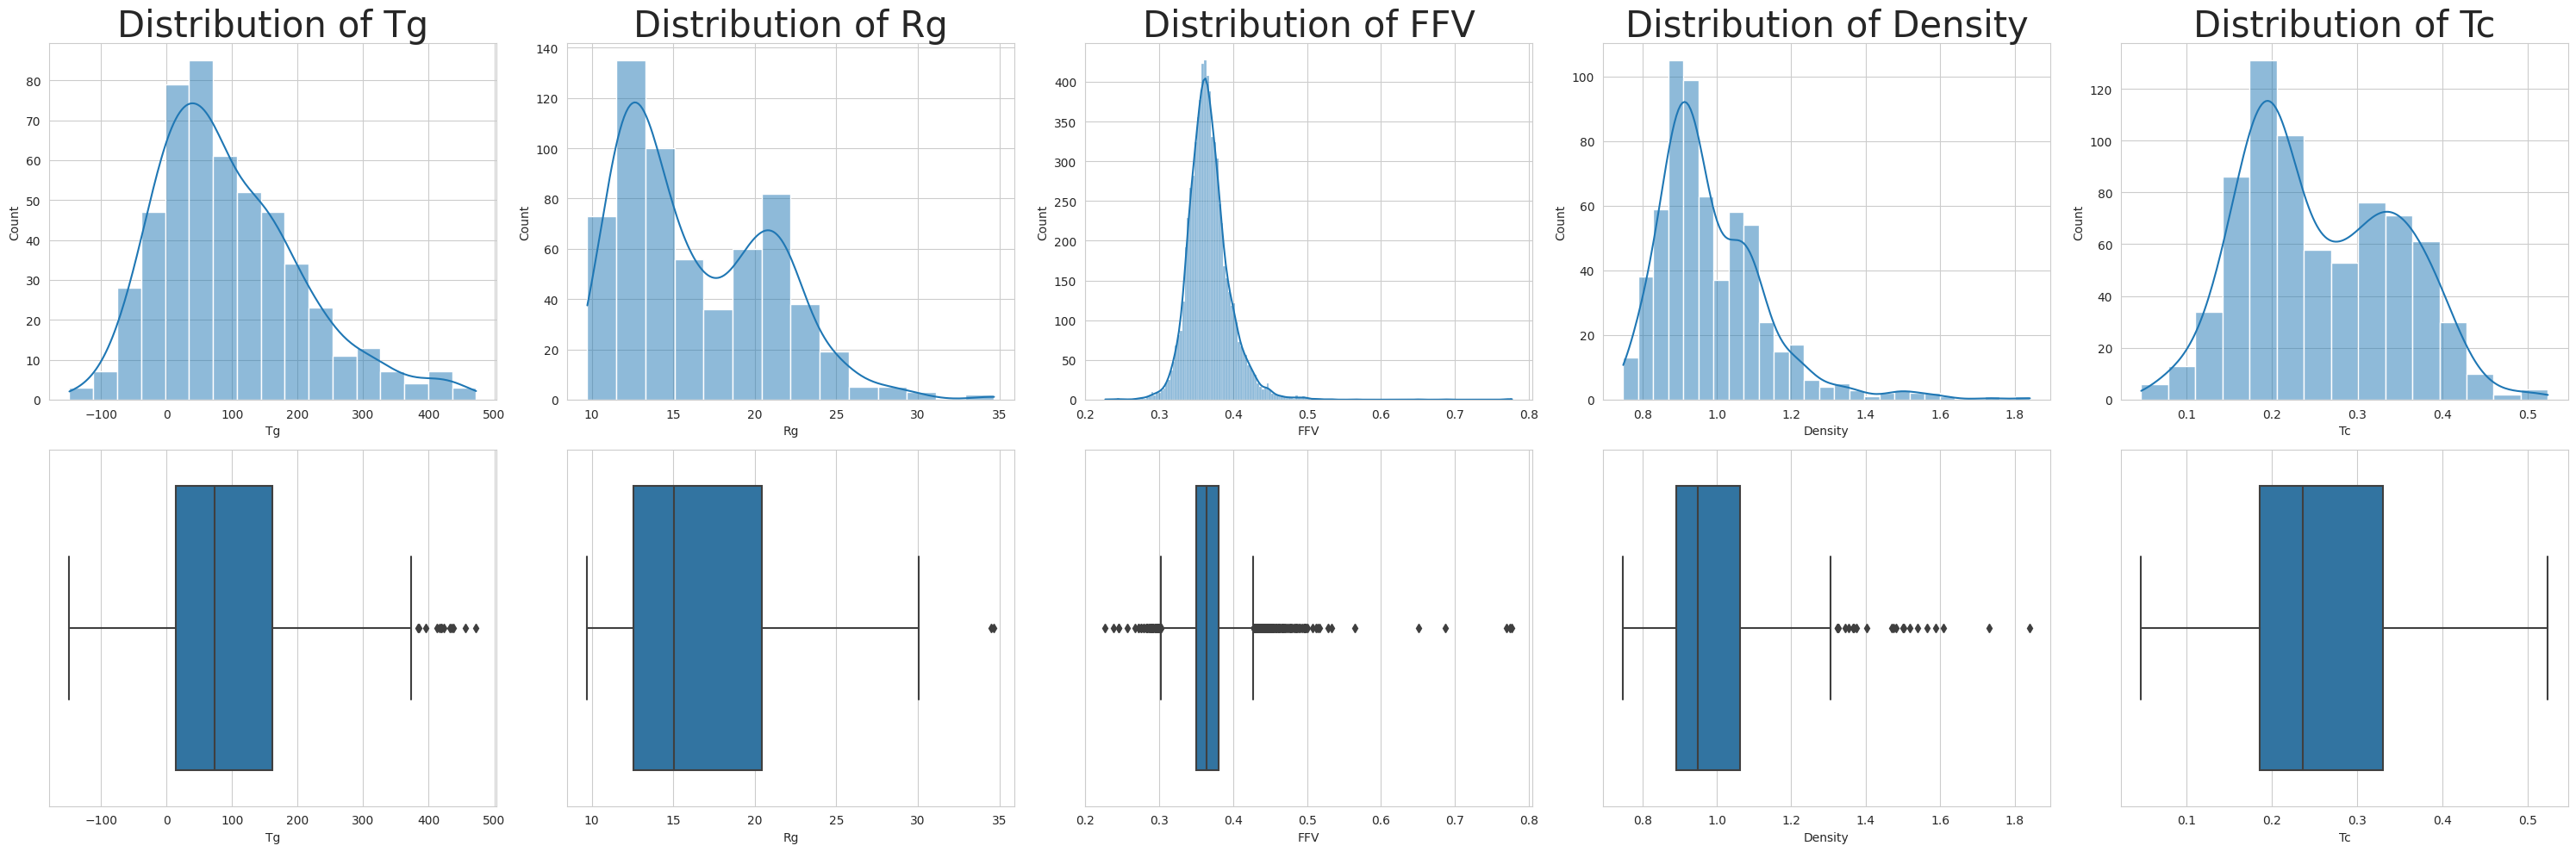

In [7]:
# Plots
fig, axes = plt.subplots(2, 5, figsize=(30, 10))
axes = axes.flatten()

for i, col in enumerate(CFG.TARGETS):
    sns.histplot(data=TRAIN_DF, x=col, ax=axes[i], kde=True)
    sns.boxplot(data=TRAIN_DF, x=col, ax=axes[i+5],)
    axes[i].set_title(f'Distribution of {col}',fontsize=30)

plt.tight_layout() # Adjust layout to prevent titles from overlapping
plt.show()

# $$ Correlations - Bivariate \ Analysis$$

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


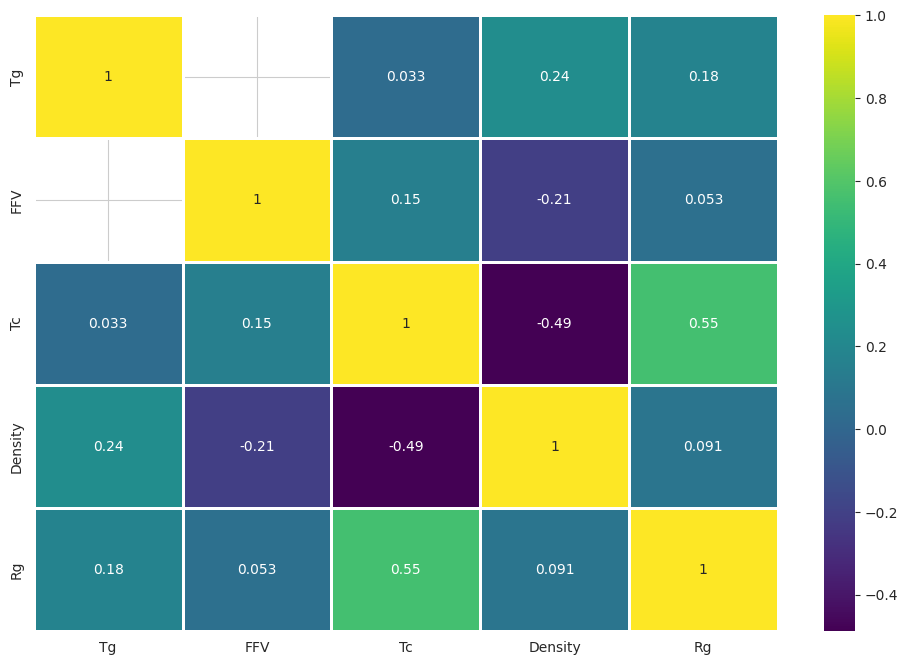

<Figure size 640x480 with 0 Axes>

In [8]:
# Create a heatmap to visualize the correlation matrix of the TRAIN_DF DataFrame
plt.figure(figsize=(12,8))
sns.heatmap(data=TRAIN_DF.corr(numeric_only=True).round(4),
            annot=True,
            cmap='viridis',
            linewidth = 2
           ); plt.show(); plt.tight_layout()

# $$Introduction \ to \ RDKit$$

## What is RDKit and Why Use It?

RDKit is an open-source chemoinformatics toolkit for representing chemical structures and calculating molecular descriptors and fingerprints from formats like SMILES strings. These descriptors capture physicochemical and structural properties of molecules, providing informative features for machine learning models that predict polymer and chemical properties. When combined with fingerprints such as Morgan fingerprints, RDKit descriptors have been shown to improve model accuracy and generalizability.

In polymer research, RDKit has been applied to predict diverse properties and understand underlying mechanisms. For example, descriptors of polyethylene terephthalate monomers were combined with time-domain NMR data to model surface properties of hydrophilic polymer coatings, with feature selection and random forest modeling identifying key contributors to performance [1](https://doi.org/10.3390/polym16060824). In another study, RDKit descriptors were combined with Morgan fingerprints to predict solubility of homopolymers and copolymers using classical machine learning models such as random forests and decision trees, improving predictive performance across multiple polymer properties [2](https://doi.org/10.1039/D4DD00290C). RDKit has also been employed for predicting glass transition temperature, density, and flammability [3](https://arxiv.org/abs/2504.00223), [4](https://pubs.acs.org/doi/10.1021/acspolymersau.1c00050).


## Getting started with SMILES and RDKit

In [9]:
# install RDKit for offline use
# !pip install /kaggle/input/rdkit-install-whl/rdkit_wheel/rdkit_pypi-2022.9.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl --quiet
!pip install /kaggle/input/rdkit-2025-3-3-cp311/rdkit-2025.3.3-cp311-cp311-manylinux_2_28_x86_64.whl --quiet

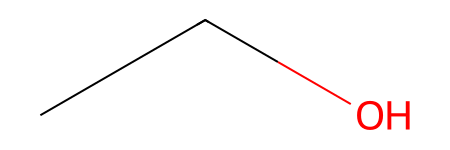

In [10]:
# Load SMILES into RDKit
from rdkit import Chem

# example
smiles = 'CCO' # ethanol
mol = Chem.MolFromSmiles(smiles)
mol

*`"CCO"` is a SMILES string.

*`Chem.MolFromSmiles` converts it to an RDKit `Mol` object, the internal representation of the molecule.

## Visualization of Molecules
The `MolsToGridImage` method is part of the RDKit `Draw` library and plays an important role in visualizing chemical structures, especially for sets of molecules. It takes a list of molecules and creates a grid image of their 2D molecular representations.

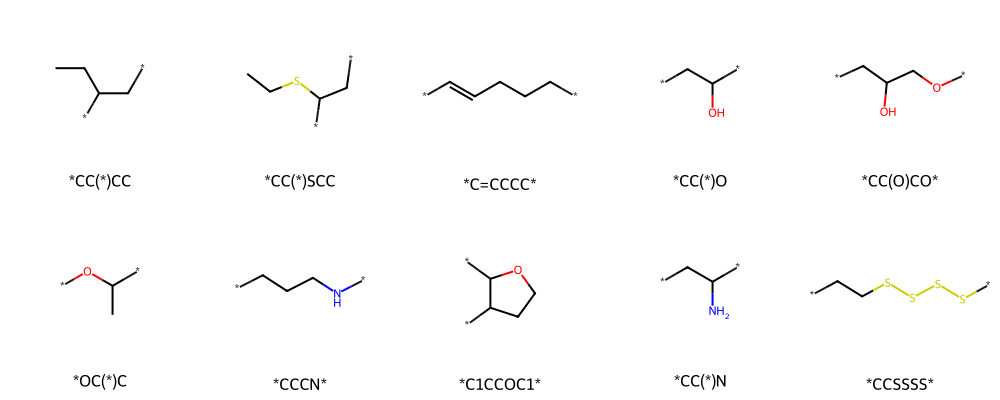

In [11]:
from rdkit.Chem import Draw

# Define sample and sample size (select short smiles for better visualization)
LENGTH_MASK = TRAIN_DF['SMILES'].apply(lambda x: len(x) < 10)
k = 10
smiles_sample = TRAIN_DF['SMILES'][LENGTH_MASK].to_list()[:k]

Draw.MolsToGridImage(
    [Chem.MolFromSmiles(mol) for mol in smiles_sample],
    molsPerRow=5,
    legends=[smiles for smiles in smiles_sample]
)

## Why “canonical SMILES”?

Canonical SMILES are a standardized, unique representation of a molecule in the SMILES format. While a single molecule can have multiple valid SMILES strings depending on atom ordering, the canonical SMILES ensures one consistent representation for each structure.

This is important for avoiding duplication in chemical databases, enabling reliable comparisons between molecules, and ensuring reproducible feature extraction in computational workflows or machine learning models.

**Example**: Ethanol can be written as `CCO` or `C(C)O` in SMILES. The canonical SMILES for ethanol is always `CCO`, regardless of how the molecule is drawn or the order of atoms in input, ensuring consistency across datasets and analyses

In [12]:
def canonical_smiles(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return Chem.MolToSmiles(mol, canonical=True)

for molecule in ["CCO","OCC","C(C)O"]:
    print(canonical_smiles(molecule))

CCO
CCO
CCO


* `Chem.MolFromSmiles(smiles)` : converts text into an RDKit Mol.

* `Chem.MolToSmiles(mol, canonical=True)` : asks RDKit for its unique canonical SMILES.

In [13]:
# switched to this to solve scoring error: https://www.kaggle.com/competitions/neurips-open-polymer-prediction-2025/discussion/590925

def canonical_smiles(smile): # To avoid duplicates, for example: canonical '*C=C(*)C' == '*C(=C*)C'
  """Completely clean and validate SMILES, removing all problematic patterns"""
  if not isinstance(smile, str) or len(smile) == 0:
      return None
  # List of all problematic patterns we've seen
  bad_patterns = [
      '[R]', '[R1]', '[R2]', '[R3]', '[R4]', '[R5]',
      "[R']", '[R"]', 'R1', 'R2', 'R3', 'R4', 'R5',
      # Additional patterns that cause issues
      '([R])', '([R1])', '([R2])',
  ]
  # Check for any bad patterns
  for pattern in bad_patterns:
      if pattern in smile:
          return np.nan
  # Additional check: if it contains ] followed by [ without valid atoms, likely polymer notation
  if '][' in smile and any(x in smile for x in ['[R', 'R]']):
      return np.nan
  try:
      mol = Chem.MolFromSmiles(smile)
      canon_smile = Chem.MolToSmiles(mol, canonical=True)
      return canon_smile
  except:
      return np.nan

TRAIN_DF['canonical'] = TRAIN_DF['SMILES'].apply(lambda s: canonical_smiles(s)); TRAIN_DF.drop(['SMILES'], axis=1) 
TEST_DF['canonical'] = TEST_DF['SMILES'].apply(lambda s: canonical_smiles(s)); TEST_DF.drop(['SMILES'], axis=1)

,canonical
id,
1109053969,*Oc1ccc(C=NN=Cc2ccc(Oc3ccc(C(c4ccc(*)cc4)(C(F)...
1422188626,*Oc1ccc(C(C)(C)c2ccc(Oc3ccc(C(=O)c4cccc(C(=O)c...
2032016830,*c1cccc(OCCCCCCCCOc2cccc(N3C(=O)c4ccc(-c5cccc6...


In [14]:
# TRAIN_DF['canonical'] = TRAIN_DF['SMILES'].apply(canonical_smiles); TRAIN_DF.drop(['SMILES'], axis=1) 
# TEST_DF['canonical'] = TEST_DF['SMILES'].apply(canonical_smiles); TEST_DF.drop(['SMILES'], axis=1)

print(TRAIN_DF.duplicated(subset='canonical').sum())
print(TEST_DF.duplicated(subset='canonical').sum())

0
0


**NOTE**: In this case there's no duplicates anyway.

## Featurization strategies
The big question is: _how do I turn molecules into numerical features for ML_?

There are three broad approaches:

### (a) Molecular Descriptors

RDKit provides ~200 standard molecular descriptors. These descriptors include various properties such as molecular weight, number of hydrogen bond acceptors/donors, number of rings, rotatable bonds, topological polar surface area (TPSA), and many others commonly used in cheminformatics and QSAR modeling.

In [15]:
from rdkit.ML.Descriptors import MoleculeDescriptors
from rdkit.Chem import Descriptors

# List all available descriptors
descriptor_names = [desc[0] for desc in Descriptors._descList]
calc = MoleculeDescriptors.MolecularDescriptorCalculator(descriptor_names)
features = calc.CalcDescriptors(mol)

pd.DataFrame([dict(zip(descriptor_names, features))])

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,7.569444,7.569444,0.25,0.25,0.406808,6.0,46.069,40.021,46.041865,20,...,0,0,0,0,0,0,0,0,0,0


### (b) Molecular Fingerprints

These are bit vectors or counts that encode molecular substructures.

#### (b1) Morgan fingerprints:
Morgan fingerprints in RDKit are a form of circular fingerprints, used to represent molecules as binary vectors based on atom neighborhoods. They encode molecular structure by considering circular substructures around atoms up to a specific radius, capturing topology and connectivity. This flexibility allows setting parameters like the radius (how far from each atom to include neighbors) and the bit vector length. Morgan fingerprints can be generated with or without chirality and include bond types.

In [16]:
from rdkit.Chem import AllChem
from rdkit.DataStructs import ConvertToNumpyArray

# Generate Morgan fingerprint
fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048)

# Convert to numpy array
arr = np.zeros((1,))
ConvertToNumpyArray(fp, arr)
print(arr[:20])

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


[13:51:36] DEPRECATION WARNING: please use MorganGenerator


* `radius=2` means “look at atom neighborhoods up to 2 bonds away.”
* `nBits=2048` means the fingerprint has length 2048 (a common size).

#### (b2) MACCS keys:
MACCS keys (Molecular ACCess System keys) are a type of chemical fingerprint used in cheminformatics to represent molecules as binary bitstrings. Each bit in the MACCS key corresponds to the presence (1) or absence (0) of a **predefined structural feature or fragment** in the molecule. These features are specific chemical substructures about the molecule, such as the presence of a particular atom, a bond type, or a ring of a certain size.

The commonly used public MACCS key set comprises 166 bits, each representing a specific substructure or characteristic. The result is a fixed-length binary fingerprint encoding these structural features, used for molecular similarity and other cheminformatics tasks.

In [17]:
from rdkit.Chem import MACCSkeys

maccs = np.array(MACCSkeys.GenMACCSKeys(mol))
maccs

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0])

Morgan fingerprints differ from MACCS keys mainly in their generation and representation approach:

* Morgan fingerprints are circular fingerprints generated by enumerating circular substructures around each atom within a specified radius, hashing these substructures into a fixed-length binary vector. They are data-driven and hashed, encoding atom neighborhoods and topology flexibly by adjusting parameters like radius and bit length.

* MACCS keys, on the other hand, are predefined structural keys with a fixed length (typically 166 bits). Each bit corresponds to a specific predefined chemical substructure or feature. The presence or absence of these features in a molecule sets the bit to 1 or 0, respectively. MACCS keys are more of a dictionary-based fingerprint representing chemically meaningful features.

### (c) Graph-based features

Some advanced workflows feed the molecular graph directly into Graph Neural Networks (GNNs). 

$$[WIP]$$ 


# $$🛠 \ Feature \ engineering$$

In [18]:
%%capture

def feature_engineering(df, smiles_col='canonical', descriptor_names=descriptor_names):
    """
    Converts SMILES strings into a DataFrame of:
      - Molecular descriptors
      - Morgan fingerprints
      - MACCS keys
    """
    # ==================== MOLECULAR DESCRIPTORS ====================
    def add_molecular_descriptors(smiles):
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            # return None
            return np.full(len(descriptor_names), np.nan)  # keep shape consistent
        return calc.CalcDescriptors(mol)
        
    # Apply transformation to each SMILES
    features = df[smiles_col].apply(add_molecular_descriptors)

    # Convert each tuple into a dict {descriptor_name: value}
    descriptors_df = pd.DataFrame(
        features.apply(lambda x: dict(zip(descriptor_names, x)) if x is not None else None).tolist(),
        index=df.index
    )

    # ==================== MORGAN FINGERPRINTS ====================
    def smiles_to_fp(smiles):    
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            # return None
            return np.zeros(nBits)
        return np.array(AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048))

    # Apply transformation to each SMILES
    fps = df[smiles_col].apply(smiles_to_fp)
    morgan_df = pd.DataFrame(fps.tolist(), index=df.index)
    morgan_df.columns = ["fp_"+str(x) for x in morgan_df.columns]

    # ==================== MACCS KEYS ====================
    def smiles_to_maccs(smiles):    
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            # return None
            return np.zeros(167)
        return np.array(MACCSkeys.GenMACCSKeys(mol))

    # Apply transformation to each SMILES
    fps = df[smiles_col].apply(smiles_to_maccs)
    maccs_df = pd.DataFrame(fps.tolist(), index=df.index)
    maccs_df.columns = ["maccs_"+str(x) for x in maccs_df.columns]
    
    # ==================== CONCATENATE ====================
    full_df = pd.concat([
        df,
        descriptors_df,
        morgan_df,
        maccs_df
    ], axis=1)
    
    return full_df

# Get df with new variables
PROCESSED_TRAIN_DF = feature_engineering(TRAIN_DF).drop(["SMILES","canonical"],axis=1)
PROCESSED_TEST_DF = feature_engineering(TEST_DF).drop(["SMILES","canonical"],axis=1)
PROCESSED_TRAIN_DF.head()

# $$ LGBM \ Model$$

In [19]:
def target_focused_data(df, targets):
    """
    Create subsets of a DataFrame, each focused on a single target variable.

    For each target in `targets`, this function:
      1. Drops all other target columns from the DataFrame.
      2. Removes rows where the current target has missing values.
      3. Returns a list of cleaned, target-specific DataFrames.

    Parameters
    ----------
    df : pandas.DataFrame
        The input DataFrame containing features and target columns.
    targets : list of str
        A list of column names corresponding to target variables in `df`.

    Returns
    -------
    list of pandas.DataFrame
        A list of DataFrames, one per target, cleaned and reduced accordingly.
    """
    subsets = []
    for target in targets:
        subset_df = (
            df.drop([t for t in targets if t != target], axis=1)
              .dropna(subset=[target])
        )
        subsets.append(subset_df)
    
    return subsets

# Apply
subsets = target_focused_data(PROCESSED_TRAIN_DF, CFG.TARGETS)
named_subsets = dict(zip(CFG.TARGETS, subsets))

In [20]:
import time
from sklearn.metrics import mean_absolute_error
import lightgbm as lgbm
from lightgbm import LGBMRegressor, early_stopping
from sklearn.model_selection import KFold

# Initialize dictionaries to store predictions from each model/target
OOF_PREDS = dict()
TEST_PREDS = dict()
SCORES_DICT = dict()

# Start model loop
for target, subset in named_subsets.items():

    # Define X,y and X_test
    X = subset.copy()
    y = X.pop(target)
    X_test = PROCESSED_TEST_DF.copy()
    
    # Initialize kf
    kf = KFold(n_splits=CFG.FOLDS, shuffle=True, random_state=CFG.SEED)
    
    # Define empty oof variables to fill
    oof_preds = np.zeros(shape = (len(X)))
    test_preds = np.zeros(shape = (len(X_test)))
    fold_scores = []
        
    scores = []

    print(f"\n{'='*20} Fitting model for target: {target} {'='*20}")
    for fold, (train_idx, valid_idx) in enumerate(kf.split(X, y.values)):
        print(f"\n{'#'*10} Fold {fold+1}/{CFG.FOLDS} {'#'*10}")
    
        # Define splits
        x_train, x_valid = X.iloc[train_idx], X.iloc[valid_idx]
        # x_train, x_valid, _ = iqr_outlier_capping(x_train, x_valid, None, columns = X.select_dtypes('number').columns.difference([target]))
        y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]
        x_test_loop = X_test.copy()

        start = time.time()

        model = LGBMRegressor(**CFG.LGBM_PARAMS)
        model.fit(x_train, y_train,
                  eval_set=[(x_train, y_train),(x_valid, y_valid)],
                  callbacks = [lgbm.early_stopping(stopping_rounds=100, verbose=-1)],
                 )
    
        # Get predictions for...
        # ---oof
        preds = model.predict(x_valid); # print(f'DEBUG TEST PROBA: {preds}')
        oof_preds[valid_idx] = preds
        # ---test
        test_preds += model.predict(x_test_loop)

        # Store fold score
        fold_score = mean_absolute_error(y_valid, preds)
        fold_scores.append(fold_score)
        print(f" Fold {fold+1}: MAE Score: {fold_score:.5f}")
        
        end = time.time()
        print(f"Fold {fold+1} finished in {end - start:.2f} seconds")
    
    mean_valid_score = np.mean(fold_scores); print(f"Mean MAE: {mean_valid_score:.3f} +- {np.std(fold_scores):.3f}")
    test_predictions = test_preds / CFG.FOLDS
    
    # Store OOF and TEST predictions
    OOF_PREDS[target] = oof_preds
    TEST_PREDS[target] = test_predictions

    # Store fold scores for target-specific evaluations
    SCORES_DICT[target] = fold_scores


==================== Fitting model for target: Tg ====================

########## Fold 1/5 ##########
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[30]	training's l1: 20.5585	valid_1's l1: 54.4591
 Fold 1: MAE Score: 54.45910
Fold 1 finished in 0.46 seconds

########## Fold 2/5 ##########
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[66]	training's l1: 8.30479	valid_1's l1: 55.8448
 Fold 2: MAE Score: 55.84482
Fold 2 finished in 0.43 seconds

########## Fold 3/5 ##########
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[37]	training's l1: 17.0017	valid_1's l1: 47.705
 Fold 3: MAE Score: 47.70500
Fold 3 finished in 0.49 seconds

########## Fold 4/5 ##########
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[30]	training's l1: 21.7395	

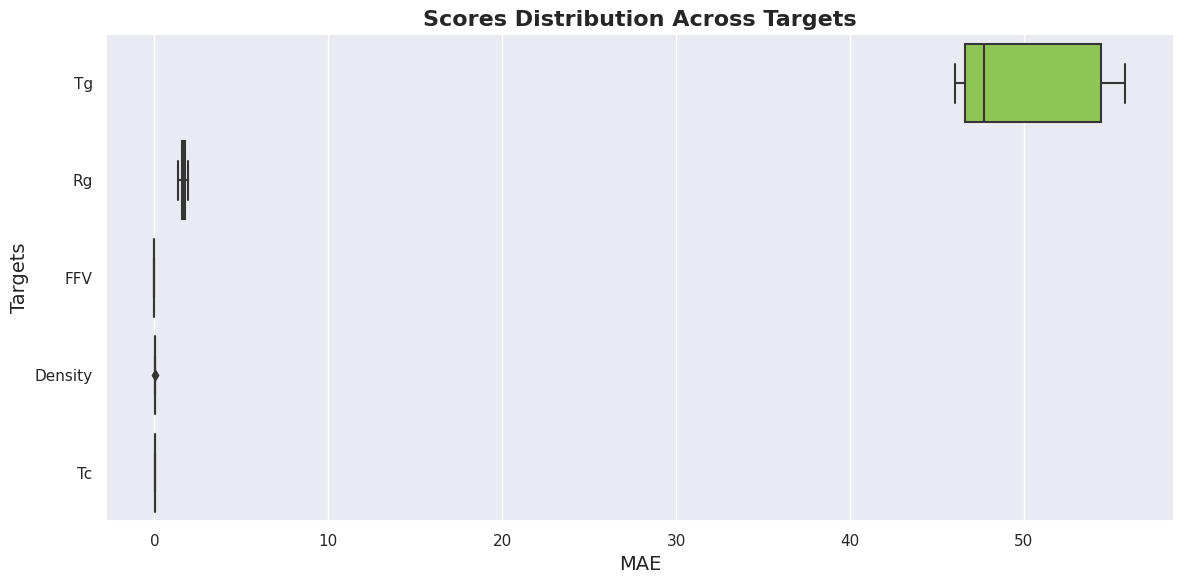

In [21]:
scores_df = pd.DataFrame(SCORES_DICT)

# Set seaborn theme
sns.set_theme(style="darkgrid")

# Boxplot
plt.figure(figsize=(12, 6))
boxplot = sns.boxplot(data=scores_df, palette='viridis_r', orient='h')

# Add titles and labels
plt.title('Scores Distribution Across Targets', fontsize=16, weight='bold')
plt.xlabel('MAE', fontsize=14)
plt.ylabel('Targets', fontsize=14)
plt.tight_layout()
plt.show()

# $$✅ Submission$$

In [22]:
TEST_PREDS

{'Tg': array([144.43723516, 141.4164843 ,  81.15625542]),
 'Rg': array([22.10461485, 20.05042175, 20.26861364]),
 'FFV': array([0.37780981, 0.37732746, 0.35000902]),
 'Density': array([1.17534827, 1.08783575, 1.12807931]),
 'Tc': array([0.18988943, 0.2445679 , 0.25751851])}

In [23]:
# Create Submission File
submission_df = pd.DataFrame(TEST_PREDS)
submission_df['id'] = TEST_DF.index

# Reorder columns
submission_df = submission_df[["id","Tg","FFV","Tc","Density","Rg"]]

# Save to CSV
submission_df.to_csv('submission.csv', index=False)

# Display results
display(submission_df)

,id,Tg,FFV,Tc,Density,Rg
0,1109053969,144.437235,0.377810,0.189889,1.175348,22.104615
1,1422188626,141.416484,0.377327,0.244568,1.087836,20.050422
2,2032016830,81.156255,0.350009,0.257519,1.128079,20.268614
